## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [2]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


### The point estimate of the ATE is -0.01. This means that the conservative group has a slightly higher chance of survival, so I would rather not get the intra aortic balloon pump.

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [3]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

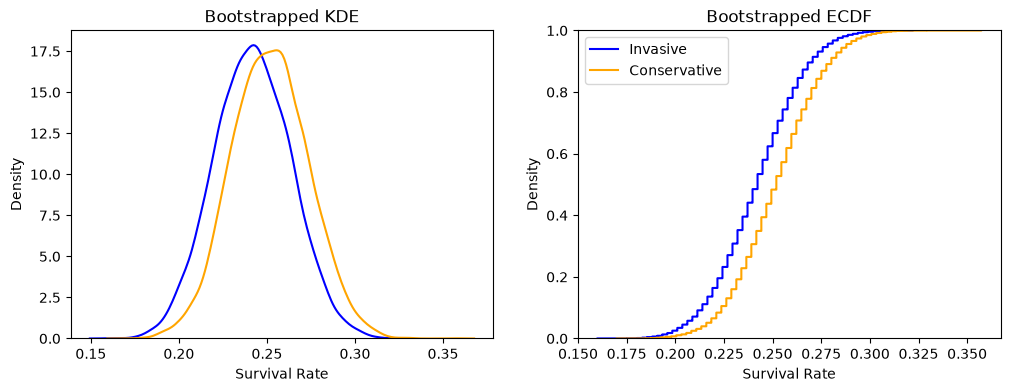

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

### In the KDE, the conservative group has its peak density at a higher survival rate than the invasive group. Similarly, the ECDF shows that at all steps, the survival rate of the conservative group is greater than that of the invasive group.

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

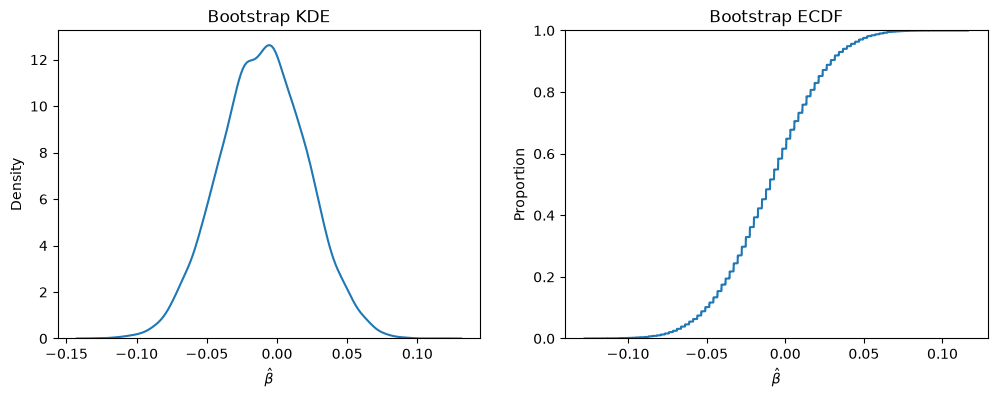

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


### The bootsrap KDE of the ATE appears to be approximately normally distributed and can take values ranging from ~-0.10 to 0.10

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [6]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06112057  0.04180691]
95% CI: [-0.07139656  0.05207643]
99% CI: [-0.08693322  0.0700913 ]


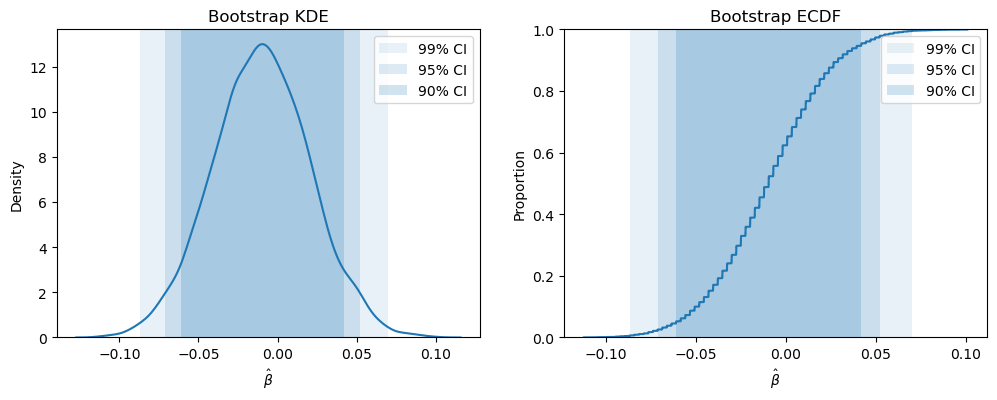

In [7]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

### Zero is in the confidence interval for all confidence levels, so we fail to reject the null hypothesis that effect size is zero at 90%, 95%, and 99% confidence. 

**6.** What have we learned about inserting balloons into hearts?

### We have learned that inserting balloons into hearts does not statistically significantly alter survival time. 

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

In [6]:
df

,Unnamed: 0,treatment,outcome
0,1,met,success
1,2,rosi,failure
2,3,rosi,success
3,4,lifestyle,success
4,5,met,success
...,...,...,...
694,695,lifestyle,failure
695,696,lifestyle,success
696,697,lifestyle,success
697,698,met,success


In [28]:
#1 
df_original = pd.read_csv('./data/diabetes.csv')
df = pd.get_dummies(df_original, columns = ['outcome'], dtype=int, drop_first=True)
print(pd.crosstab( df_original['treatment'], df_original['outcome']), '\n')

met_avg = df.loc[df['treatment'] == 'met', 'outcome_success'].mean()
rosi_avg = df.loc[ df['treatment'] == 'rosi', 'outcome_success'].mean()
lifestyle_avg = df.loc[ df['treatment'] == 'lifestyle', 'outcome_success'].mean()
print(
    f'Metformin average: {met_avg}\n'
    f'Rosiglitazone average: {rosi_avg}\n'
    f'Lifestyle adjustment average: {lifestyle_avg}\n'
)

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 

Metformin average: 0.4827586206896552
Rosiglitazone average: 0.6137339055793991
Lifestyle adjustment average: 0.5341880341880342



In [43]:
#2
R = 10_000

df_a = df.loc[ df['treatment'] == 'met',:]
df_b = df.loc[ df['treatment'] == 'rosi',:]
df_c = df.loc[df['treatment'] == 'lifestyle',:]
outcome_a = []
outcome_b = []
outcome_c = []
ate_met_rosi = []
ate_met_lifestyle = []
ate_rosi_lifestyle = []
#ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)
    df_ct = df_c.sample(frac = 1.0, replace = True)

    ## Evaluate outcomes:
    oat = df_at['outcome_success'].mean() # Mean outcome for A
    obt = df_bt['outcome_success'].mean() # Mean outcome for B    
    oct = df_ct['outcome_success'].mean() # Mean outcome for C

    ## Compute ATE:
    ate_ab = oat - obt # Compute ATE for this bootstrap sample
    ate_ac = oat - oct
    ate_bc = obt - oct 
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    outcome_c.append(oct)

    ate_met_rosi.append(ate_ab) # Save new value
    ate_met_lifestyle.append(ate_ac)
    ate_rosi_lifestyle.append(ate_bc)

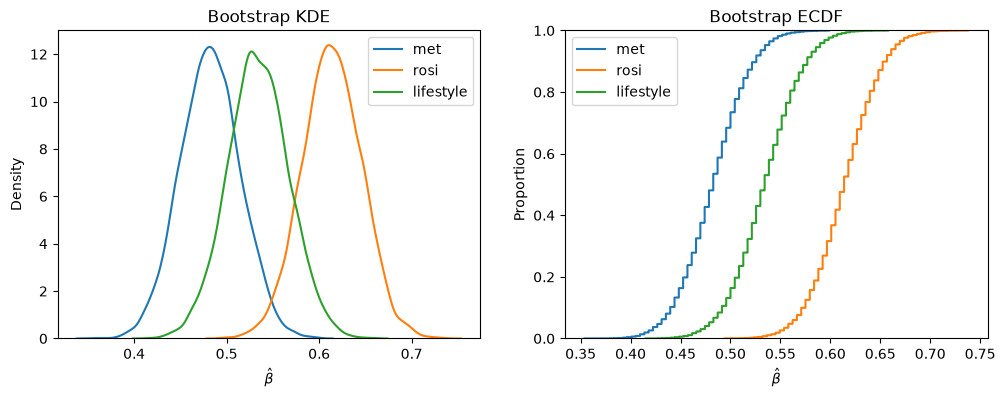

In [44]:
#3
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(outcome_a, ax=ax[0], label = 'met')
sns.kdeplot(outcome_b, ax=ax[0], label = 'rosi')
sns.kdeplot(outcome_c, ax=ax[0], label = 'lifestyle')
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(outcome_a, ax=ax[1], label='met')
sns.ecdfplot(outcome_b, ax=ax[1], label = 'rosi')
sns.ecdfplot(outcome_c, ax=ax[1], label = 'lifestyle')
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

plt.show()

Rosiglitazone treatment seems to have the greatest success rate, followed by lifestyle changes and Metformin.

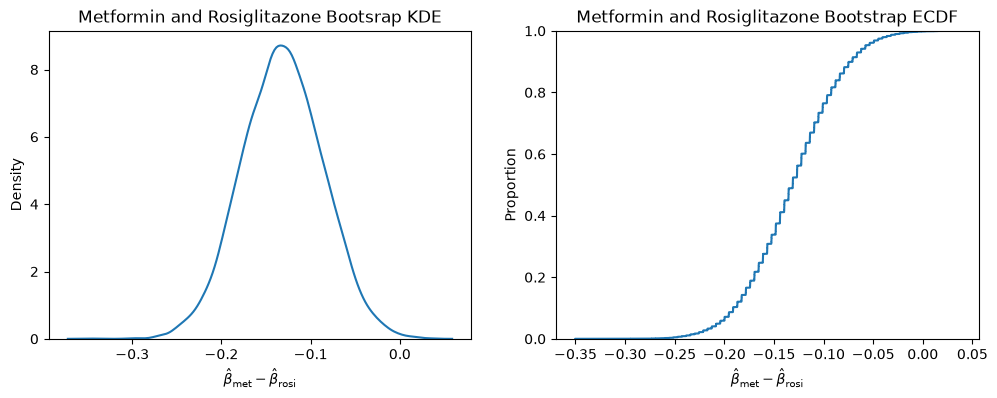

In [55]:
#4.

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(ate_met_rosi, ax=ax[0])
sns.ecdfplot(ate_met_rosi, ax=ax[1])
ax[0].set_xlabel(r"$\hat{\beta}_{\mathrm{met}} - \hat{\beta}_{\mathrm{rosi}}$")
ax[0].set_title("Metformin and Rosiglitazone Bootsrap KDE")

ax[1].set_xlabel(r"$\hat{\beta}_{\mathrm{met}} - \hat{\beta}_{\mathrm{rosi}}$")
ax[1].set_title("Metformin and Rosiglitazone Bootstrap ECDF")

plt.show()

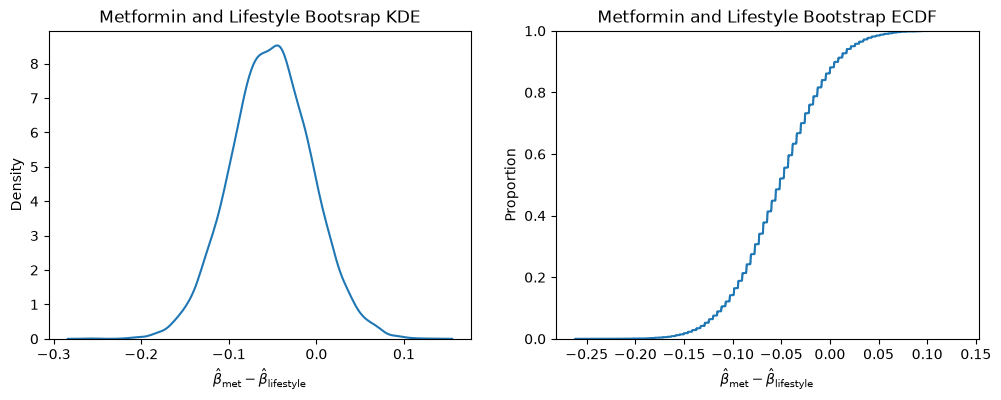

In [58]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(ate_met_lifestyle, ax=ax[0])
sns.ecdfplot(ate_met_lifestyle, ax=ax[1])

ax[0].set_xlabel(r"$\hat{\beta}_{\mathrm{met}} - \hat{\beta}_{\mathrm{lifestyle}}$")
ax[0].set_title("Metformin and Lifestyle Bootsrap KDE")

ax[1].set_xlabel(r"$\hat{\beta}_{\mathrm{met}} - \hat{\beta}_{\mathrm{lifestyle}}$")
ax[1].set_title("Metformin and Lifestyle Bootstrap ECDF")

plt.show()

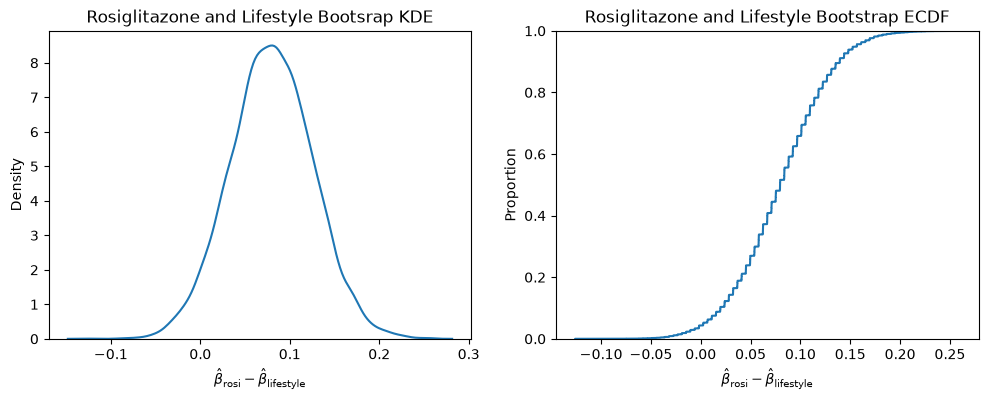

In [59]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(ate_rosi_lifestyle, ax=ax[0])
sns.ecdfplot(ate_rosi_lifestyle, ax=ax[1])

ax[0].set_xlabel(r"$\hat{\beta}_{\mathrm{rosi}} - \hat{\beta}_{\mathrm{lifestyle}}$")
ax[0].set_title("Rosiglitazone and Lifestyle Bootsrap KDE")

ax[1].set_xlabel(r"$\hat{\beta}_{\mathrm{rosi}} - \hat{\beta}_{\mathrm{lifestyle}}$")
ax[1].set_title("Rosiglitazone and Lifestyle Bootstrap ECDF")

plt.show()

In [66]:
#5
print(f'ATE Metformin - Rosiglitazone 90% Confidence Interval: {np.percentile(ate_met_rosi, [5.0, 95.0])}')
print(f'ATE Metformin - Rosiglitazone 95% Confidence Interval: {np.percentile(ate_met_rosi, [2.5, 97.5])}')
print(f'ATE Metformin - Rosiglitazone 99% Confidence Interval: {np.percentile(ate_met_rosi, [0.5, 99.5])}')

print(f'ATE Metformin - Lifestyle 90% Confidence Interval: {np.percentile(ate_met_lifestyle, [5.0, 95.0])}')
print(f'ATE Metformin - Lifestyle 95% Confidence Interval: {np.percentile(ate_met_lifestyle, [2.5, 97.5])}')
print(f'ATE Metformin - Lifestyle 99% Confidence Interval: {np.percentile(ate_met_lifestyle, [0.5, 99.5])}')

print(f'ATE Rosiglitazone - Lifestyle 90% Confidence Interval: {np.percentile(ate_rosi_lifestyle, [5.0, 95.0])}')
print(f'ATE Rosiglitazone - Lifestyle 95% Confidence Interval: {np.percentile(ate_rosi_lifestyle, [2.5, 97.5])}')
print(f'ATE Rosiglitazone - Lifestyle 99% Confidence Interval: {np.percentile(ate_rosi_lifestyle, [0.5, 99.5])}')



ATE Metformin - Rosiglitazone 90% Confidence Interval: [-0.20423265 -0.05779192]
ATE Metformin - Rosiglitazone 95% Confidence Interval: [-0.22127053 -0.04086457]
ATE Metformin - Rosiglitazone 99% Confidence Interval: [-0.24722519 -0.01483647]
ATE Metformin - Lifestyle 90% Confidence Interval: [-0.12853669  0.02531499]
ATE Metformin - Lifestyle 95% Confidence Interval: [-0.14157825  0.03872034]
ATE Metformin - Lifestyle 99% Confidence Interval: [-0.17141928  0.06867116]
ATE Rosiglitazone - Lifestyle 90% Confidence Interval: [0.00251275 0.15654323]
ATE Rosiglitazone - Lifestyle 95% Confidence Interval: [-0.01038159  0.16954624]
ATE Rosiglitazone - Lifestyle 99% Confidence Interval: [-0.03615054  0.20373436]


The most significant relationship is between met and rosi, where rosi is statistically significantly better at preventing type 2 diabetes than met at a 99% confidence level. The difference between rosi and lifestyle is significantly significant at a 90% confidence level, but is insignificant at 95%. The difference between met and lifestyle is statistically insignificant at a 90% confidence level. From these confidence intervals, we can conclude that Rosiglitazone is the most effective treatment for reducing the progression from prediabetes to Type 2 Diabetes.

6. 

This trial attempts to investigate the effectiveness of three treatments tested for reducing progression from prediabetes to Type 2 Diabetes. Comparisons will only be made for the effectiveness between treatments, as there is no control group to compare the effectiveness of treatment against no treatment. These treatments are Metformin, Rosiglitazone, and lifestyle changes. From a cursory look at the data, the success rate for Rosiglitazone (61.37%) is noticeably higher than the success rates for Metformin (48.27%) and lifestyle adjustment (53.41%). Our pre-bootstrapping observations are consistent with the bootstrapped KDEs and ECDFs, which indicate the greatest $\hat{\beta}$ estimate for Rosiglitazone, followed by lifestyle changes and finally Metformin. 

For further analysis, we next determine which treatments are significantly different from each other, if any, by determining the significance of average treatment effects (ATEs) for each combination of treatments. The first comparison is between Metformin and Rosiglitazone. Examining the bootstrap KDE reveals that Rosiglitazone's ATE is larger than Metformin's, with a peak density of about -0.15. To determine whether or not this difference is significant, we examine the 90%, 95%, and 99% confidence intervals. The confidence intervals reveal that the difference between Metformin and Rosiglitazone is statistically significant at a 99% confidence level, as the interval does nto contain zero. 

The next comparison we examine is between Metformin and lifestyle changes. Looking at the KDE for the difference between ATEs, 0 appears to be less extreme than would be required for statistical significance. This is confirmed by the confidence intervals, as Metformin and lifestyle changes are not statistically different from one another at a 90% confidence level. Lastly, we examined the difference between Rosiglitazone and lifestyle changes. This KDE is not very revealing, and examining the confidence interval shows that the difference between Rosiglitazone and lifestyle changes is statistically significant only at a 90% confidence level. This is somewhat surprising given the large difference between success rates of Rosiglitazone and lifestyle adjustment examined previously.

The overall results were mostly in line with the pre-bootstrapping predictions. At first glance, doctors may be inclined to prescribe Rosiglitazone right out of the gate. However, we must be careful when prescribing medications and take all factors into consideration. Metformin may be prescribed more than Rosiglitazone is that the former is less powerful and has less severe side effects, whereas the latter has higher effectiveness but worse side effects, such as weight gain and heart failure. Another factor to consider is cost, as lifestyle changes have a much lower cost than a medication. There are many different angles to take into account when making analyses and prescribing medication, but examining this trial and using other data can help lead doctors to the correct decision.